In [1]:
######################################################
#    FIS616 Introdução à Computação em Física
#
#                   02/2026
#
#           
#           
#           Prof. V.B. Nascimento
#                   @UFMG
#
#  
# Referência: 
#  Numerical Python: Scientific Computing and 
#  Data Science Applications with Numpy, SciPy
#  and Matplotlib
#                2nd Edition
#             Robert Johansson
######################################################

######################################################
#
#               
#       "Chapter 4 - Plotting and Visualization"
#              Visualização de Gráficos 
######################################################


#                   MATPLOTLIB (Pyplot)
# Visualização de gráficos 2D e 3D de alta qualidade 
# usando a biblioteca Matplotlib (www.matplotlib.org)
#



In [2]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt

# Definição da função Rosenbrock
def rosenbrock(x):
    return 100 * (x[1] - x[0]**2)**2 + (1 - x[0])**2


In [3]:
######################################################################################################
# ALUNO : Daniel Marques Diniz Maia
# MATRÍCULA : 2026061836
# TURMA : TM
######################################################################################################

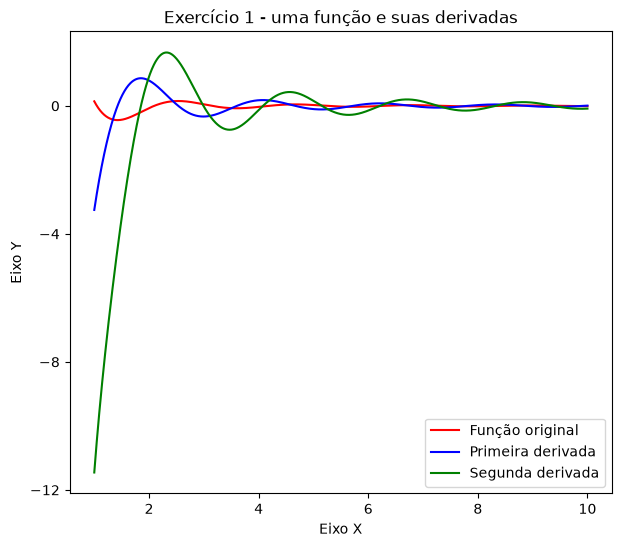

In [4]:
# 1) Faça um gráfico da função y = (1/x^2) * sen(3*x), assim como de suas derivadas de ordem um e dois. 
####################################################################################################################

# Gerando os dados. y é a função original, y1 sua primeira derivasda e y2 sua segunda
x = np.linspace(1,10,1001)
y = [(1/a**2) * np.sin(3*a) for a in x]
y1 = [(3*np.cos(3*a)/a**2) - (2*np.sin(3*a)/a**3) for a in x]
y2 = [(12*np.cos(3*a)/a**3) - (6*np.sin(3*a)/a**4) + (9*np.sin(3*a)/a**2) for a in x]

# Gerando o gráfico
fig,ax = plt.subplots(figsize=(7,6))
ax.set_xlabel('Eixo X')
ax.set_ylabel('Eixo Y')
ax.xaxis.set_major_locator(mpl.ticker.MaxNLocator(5))
ax.yaxis.set_major_locator(mpl.ticker.MaxNLocator(4))
ax.set_title('Exercício 1 - uma função e suas derivadas')
ax.plot(x, y, color='r', label = "Função original")
ax.plot(x, y1, color='blue', label = "Primeira derivada")
ax.plot(x, y2, color='g', label = "Segunda derivada")
plt.legend()
plt.show()

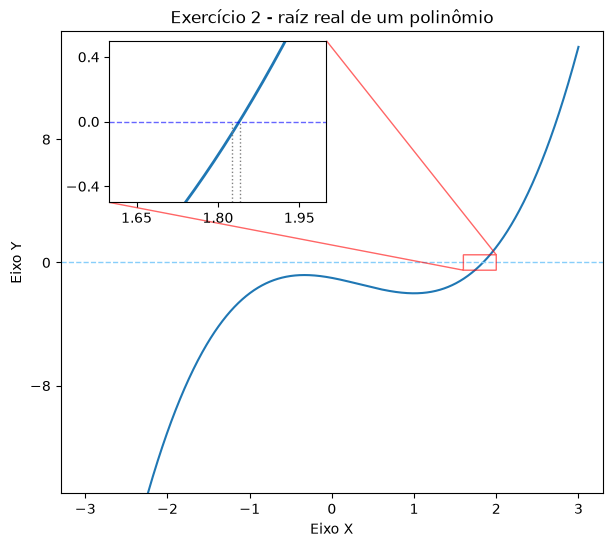

In [5]:
# 2) Através de análise gráfica localize as raízes de x**3-x**2+1 = x+2.  
# Faça um gráfico mostrando, via um "inset", uma das raízes. 
####################################################################################################################

# Gerando os dados
x = np.linspace(-3,3,1000)
y = [(a**3 - a**2 - a - 1) for a in x]

# Gerando o gráfico principal
fig,ax = plt.subplots(figsize=(7,6))
ax.set_xlabel('Eixo X')
ax.set_ylabel('Eixo Y')
ax.set_ylim(-15,15)
ax.xaxis.set_major_locator(mpl.ticker.MaxNLocator(7))
ax.yaxis.set_major_locator(mpl.ticker.MaxNLocator(4))
ax.set_title('Exercício 2 - raíz real de um polinômio')
ax.plot(x, y)
ax.axhline(0, color='lightskyblue',ls='--', lw=1,)


# Gerando o inset
axins = ax.inset_axes([0.09, 0.63, 0.4, 0.35])
axins.xaxis.set_major_locator(mpl.ticker.MaxNLocator(3))
axins.yaxis.set_major_locator(mpl.ticker.MaxNLocator(3))
axins.plot(x,y, lw=2)
axins.set_xlim(1.6,2)
axins.set_ylim(-0.5,0.5)
axins.axhline(color='blue', ls='--', lw=1, alpha=0.6)
axins.axvline(x=1.825, ymax = 0.5, color='grey', ls=':',lw=1)
axins.axvline(x=1.84, ymax = 0.5, color='grey', ls=':',lw=1)
ax.indicate_inset_zoom(axins, edgecolor="r", alpha=0.6) # indicando a região do zoom

plt.show()

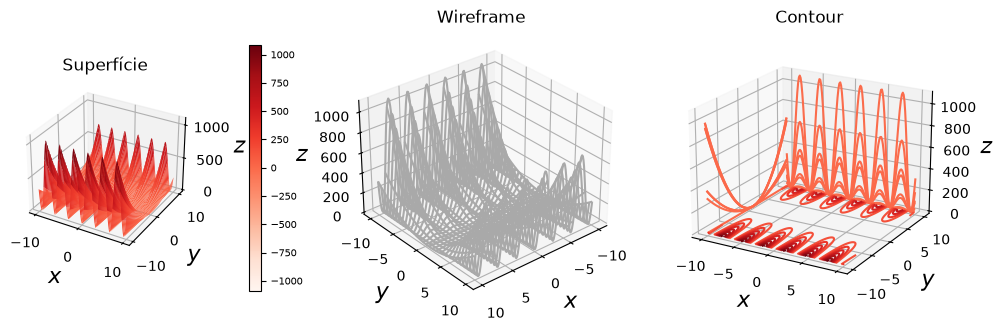

In [6]:
# 3) Faça gráficos 3D de z = sen(x)^2 * (3*y - 3)**2 do tipo "surface", "wireplot" e "contour". O gráfico deverá ser no intervalo
# -10 < x < 10 e -10 < y < 10. 
####################################################################################################################

# CORRIGIR AS LEGENDAS AAAAAAA

# Gerando os dados
x = y = np.linspace(-10,10,150)
X, Y = np.meshgrid(x, y)
Z = (np.sin(X)**2)*((3*Y - 3)**2)


# Criando os gráficos (colocar a colorbar e as legendas direito)
def title_labels(ax, title):
    ax.set_title(title)
    ax.set_xlabel("$x$", fontsize=16)
    ax.set_ylabel("$y$", fontsize=16)
    ax.set_zlabel("$z$", fontsize=16) 

fig,axes = plt.subplots(1,3, figsize=(12,4), subplot_kw={'projection': '3d'})
norm = mpl.colors.Normalize(-abs(Z).max(), abs(Z).max())

# Primeiro gráfico - superfície

p = axes[0].plot_surface(X, Y, Z, antialiased=True, norm=norm, cmap=mpl.cm.Reds)
cb = fig.colorbar(p, ax=axes[0], shrink=0.8, pad=0.2,)
cb.ax.tick_params(labelsize=7)
title_labels(axes[0],'Superfície')

# Segundo gráfico - wireframe rotacionado

q = axes[1].plot_wireframe(X, Y, Z, rstride=5, cstride=5, antialiased=True, color="darkgrey")
axes[1].view_init(elev=30, azim=50)
title_labels(axes[1], "Wireframe")

# Terceiro gráfico - contour plot

axes[2].contour(X, Y, Z, zdir='y', offset=10, norm=norm, cmap=mpl.cm.Reds)
axes[2].contour(X, Y, Z, zdir='x', offset=-10, norm=norm, cmap=mpl.cm.Reds)
axes[2].contour(X, Y, Z, zdir='z', offset=0, norm=norm, cmap=mpl.cm.Reds)
axes[2].view_init(elev=20, azim=-60)
title_labels(axes[2], "Contour")

plt.show()

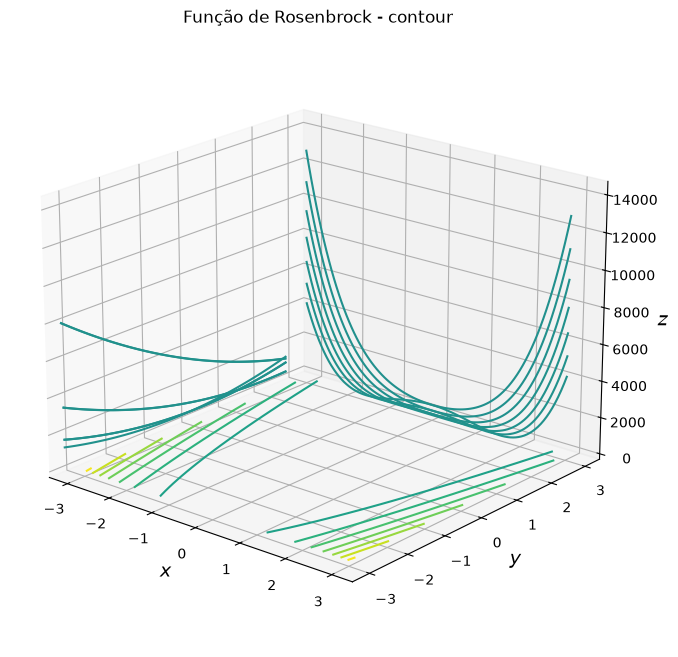

In [7]:
# 4) Faça um gráfico tipo contour plot da função de Rosenbrock: f(x,y) = (a - x)**2 + b(y - x**2)**2 com a = 1 e b = 100. 
# O intervalo será de -3 < x < 3  e -3 < y < 3. 
###################################################################################################################

# Gerando os dados
x = y = np.linspace(-3,3,100)
X,Y = np.meshgrid(x,y)
Z = 100 * (Y - X**2)**2 + (1 - X)**2

# Gerando o gráfico

fig,ax = plt.subplots(figsize=(8,8), subplot_kw={'projection': '3d'})
norm = mpl.colors.Normalize(-abs(Z).max(), abs(Z).max())

ax.set_title('Função de Rosenbrock - contour')
ax.set_xlabel("$x$", fontsize=14)
ax.set_ylabel("$y$", fontsize=14)
ax.set_zlabel("$z$", fontsize=14) 

ax.contour(X, Y, Z, zdir='x', offset=-3.5, norm=norm, cmap=mpl.cm.viridis)
ax.contour(X, Y, Z, zdir='y', offset=3, norm=norm, cmap=mpl.cm.viridis)
ax.contour(X, Y, Z, zdir='z', offset=0, norm=norm, cmap=mpl.cm.viridis)
ax.view_init(elev=20, azim=-50)

plt.show()


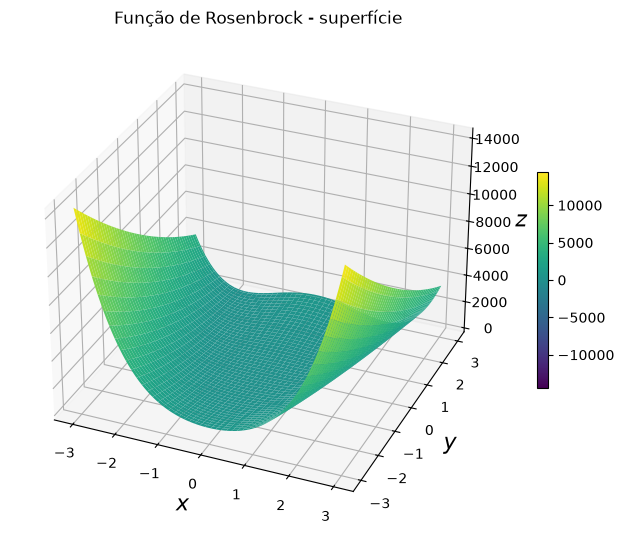

In [8]:
# 5) Faça um gráfico tipo "surface" da função de Rosenbrock: f(x,y) = (a - x)**2 + b(y - x**2)**2 com a = 1 e b = 100. 
# O intervalo será de -3 < x < 3  e -3 < y < 3. 
###################################################################################################################

# Gerando os dados
x = y = np.linspace(-3,3,100)
X,Y = np.meshgrid(x,y)
Z = 100 * (Y - X**2)**2 + (1 - X)**2

# Gerando o gráfico

fig,ax = plt.subplots(figsize=(8,8), subplot_kw={'projection': '3d'})
norm = mpl.colors.Normalize(-abs(Z).max(), abs(Z).max())

ax.set_title('Função de Rosenbrock - superfície')
ax.set_xlabel("$x$", fontsize=16)
ax.set_ylabel("$y$", fontsize=16)
ax.set_zlabel("$z$", fontsize=16)

p = ax.plot_surface(X, Y, Z, antialiased=True, norm=norm, cmap=mpl.cm.viridis)
cb = fig.colorbar(p, shrink=0.35)
ax.view_init(azim=-67)
